# Notebook 3: The agent
**IDS 560, Group 4, M5 inventory agent (v4).** Runs the agent on order decisions and on the managers' questions, and checks every answer. This is the only notebook that calls the language model (about 30 requests: 10 orders + 20 questions; OpenRouter's free tier allows 50 a day).

1. **Setup:** loads the M5 data, the forecast cube and segment files, the library from notebook 1 and the relevance cut-off from notebook 2.
2. **Scenario orders (no model calls):** ten order decisions, checked before the model is involved.
3. **The agent on the orders + validation matrix.**
4. **The managers' questions + validation matrix:** tests 37–56; forecast questions get the **forecast-data lookup**.
5. **Save.**

**How an order is made** (code in `rag_common.py`):
- **Forecast:** the latest weekly LightGBM forecast from the forecast cube made on or before the decision date (Recent Mean fallback, labelled, if the cube doesn't cover it).
- **Ordering rule:** order up to 14 days of expected demand plus safety stock (95th percentile of the item's own past forecast errors), minus stock on hand.
- **Segments:** demand type and volume level (2011–2014 sales) and the model's error for that segment so far.
- **Flags and hold rule:** `NEW_ITEM` (no sales or under 8 weeks), `POSSIBLE_STOCKOUT` and `POSSIBLY_DISCONTINUED` (a zero-sales run with under a 1-in-1,000 chance). Held orders recommend **0 until checked**, plus the quantity to order if confirmed.
- **New-item forecast:** similar items (department, store or state, category, price level), widening the group until 5 match, shifting to the item's own sales over 8 weeks (method chosen by the simulation in notebook 4).
- **Forecast confidence:** High / Medium / Low from the segment's error so far, the width of the forecast range and the length of sales history; held orders are Low.
- **The language model** only explains: it gets the order and an **item profile** passage [E1], plus retrieved evidence, and must keep the computed quantity.

## 1. Setup
Change settings with `rc.NAME = value`, e.g. `rc.OPENROUTER_MODEL = "..."` to try another free model. Add `OPENROUTER_API_KEY` in Colab's Secrets panel (key icon on the left).

In [1]:
!pip -q install sentence-transformers openai pypdf
import sys, importlib
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
RAG_FILES = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/"   # rag_common.py lives here
sys.path.insert(0, RAG_FILES)
import rag_common as rc
importlib.reload(rc)
rc.setup(m5=True, forecasts=True, library=True)
from rag_common import *
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

Mounted at /content/drive
M5 data: 30,490 series x 1,941 days | prices for 79% of series-weeks
Forecast cube: 15,245 series, 72 weekly forecasts (2014-12-31 to 2016-05-12), 14 days each
Segments: 15,245 series | model error by segment: 2,130 rows
Past launches: 16,610 | new-item method: cascade + own sales


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (15 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Library: 7,537 passages from 5,000 documents | reranker on | RELEVANCE_MIN 0.015
Setup done in 101s | files are read from and saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/ (names end in _v4)


## 2. Scenario orders (no model calls)
Ten order decisions, each on a weekly forecast date (so the full 14-day forecast is used). Items are picked automatically from the forecasting model's 50% sample: the best-selling item of the category at that store, a rarely sold one, one with a recent run of zero sales, a newly launched item, and one that stopped selling. Stock on hand is one week of forecast demand. The table shows the forecast used, segment, computed and recommended quantity, hold, flags, confidence and evidence (no passage may be from the future).

In [2]:
IN_SAMPLE = ids["id"].isin(SAMPLE_IDS).to_numpy() if SAMPLE_IDS else np.ones(len(ids), bool)   # the forecasting model's 50% sample

def pick_item(store_id, cat, as_of, kind="top"):
    end = int(day_index[pd.Timestamp(as_of)])
    rows = np.flatnonzero((ids["store_id"] == store_id).to_numpy() & (ids["cat_id"] == cat).to_numpy() & IN_SAMPLE)
    last = vals[rows, max(0, end - 364): end + 1]
    if kind == "top":
        return ids["item_id"].iloc[rows[np.argmax(last.sum(1))]]
    sale_days = (last > 0).sum(1)
    pool = rows[(sale_days >= 12) & (sale_days <= 30)]                     # sells on roughly 1 to 2.5 days a month
    return ids["item_id"].iloc[pool[0] if len(pool) else rows[np.argmin(np.abs(sale_days - 24))]]

def zero_run_item(store_id, as_of):
    end = int(day_index[pd.Timestamp(as_of)])
    rows = np.flatnonzero((ids["store_id"] == store_id).to_numpy() & IN_SAMPLE)
    recent, before = vals[rows, end - 20: end + 1], vals[rows, end - 200: end - 20]
    pool = rows[(recent.sum(1) == 0) & ((before > 0).sum(1) > 60)]
    return ids["item_id"].iloc[pool[0]] if len(pool) else None

def new_item_pick(as_of, min_days=14, max_days=42):
    """Any store: the best-selling item in the sample whose first sale was 2 to 6 weeks before as_of."""
    end = int(day_index[pd.Timestamp(as_of)])
    pos = vals[:, : end + 1] > 0
    first = np.where(pos.any(1), pos.argmax(1), -1)
    rows = np.flatnonzero(IN_SAMPLE & (first >= end - max_days + 1) & (first <= end - min_days + 1))
    if len(rows) == 0:
        return None
    r = rows[np.argmax(vals[rows, : end + 1].sum(1))]
    return ids["item_id"].iloc[r], ids["store_id"].iloc[r]

def stopped_item_pick(as_of, min_run=60):
    """Any store: an item in the sample that sold on many days in the year before its last sale, then nothing for min_run+ days."""
    end = int(day_index[pd.Timestamp(as_of)])
    recent = vals[:, end - min_run + 1: end + 1].sum(1)
    before = (vals[:, max(0, end - min_run - 364): end - min_run + 1] > 0).sum(1)
    rows = np.flatnonzero(IN_SAMPLE & (recent == 0) & (before >= 60))
    if len(rows) == 0:
        return None
    r = rows[np.argmax(before[rows])]
    return ids["item_id"].iloc[r], ids["store_id"].iloc[r]

SCENARIOS = [                                   # category, store, decision date (a weekly forecast date), which item
    ("HOBBIES",  "WI_2", "2015-01-07", "top"),           # Wisconsin winter, after the holidays
    ("FOODS",    "TX_1", "2015-08-05", "top"),           # Texas summer, SNAP days early in the month
    ("FOODS",    "TX_3", "2015-05-27", "top"),           # just after the Texas Memorial Day floods (storm reports dated before)
    ("FOODS",    "CA_1", "2015-11-18", "top"),           # Thanksgiving in the window
    ("FOODS",    "CA_1", "2015-12-16", "top"),           # Christmas in the window
    ("HOUSEHOLD","TX_2", "2015-06-03", "intermittent"),  # rarely sold item
    (None,       "WI_1", "2015-09-02", "zero_run"),      # recent run of zero sales: possible stock-out, should be held
    ("HOUSEHOLD","CA_2", "2016-05-05", "top"),           # 2016 test period
    (None,       None,   "2015-07-01", "new_item"),      # launched 2 to 6 weeks earlier, any store: held, with a new-item forecast
    (None,       None,   "2015-09-30", "stopped"),       # sold regularly, then nothing for 60+ days: possibly discontinued, held
]

def scenario_items(scenarios=None):
    """The item picked for each scenario (same rule every time, so every run uses the same items)."""
    out = []
    for cat, store, as_of, kind in scenarios or SCENARIOS:
        if kind == "zero_run":
            item = zero_run_item(store, as_of)
        elif kind in ("new_item", "stopped"):
            pick = new_item_pick(as_of) if kind == "new_item" else stopped_item_pick(as_of)
            item, store = pick if pick else (None, None)
        else:
            item = pick_item(store, cat, as_of, kind)
        if item is None:
            print("No suitable item in the sample for", kind, store or "", as_of); continue
        out.append((item, store, as_of, kind))
    return out

SCENARIO_ITEMS = scenario_items()

In [3]:
scenario_out, SCENARIO_RESULTS = [], {}
for item, store, as_of, kind in SCENARIO_ITEMS:
    fc = baseline_forecast(item, store, as_of)
    res = recommend(item, store, as_of, on_hand=int(round(fc["mean"][:7].sum())), forecast=fc, call_llm=False)
    SCENARIO_RESULTS[(item, store, as_of)] = res
    ev = res["evidence"].iloc[1:]
    q = res["order"]
    scenario_out.append({"scenario": kind, "item": item, "store": store, "as_of": as_of,
                         "forecast": ("New-item forecast" if res["forecast"].get("new_item_forecast")
                                      else res["forecast"]["model"].split(",")[0].split(" (")[0]),
                         "segment": f"{res['segment']['demand_type']} / {res['segment']['volume_level']}",
                         "computed_qty": q["computed_order_qty"], "recommended_qty": q["order_qty"], "hold": q["hold"],
                         "if_confirmed_qty": q.get("if_confirmed_order_qty"), "flags": ", ".join(f["code"] for f in res["flags"]) or "",
                         "confidence": res["confidence"]["level"], "evidence_items": len(ev),
                         "future_evidence": int((ev["published"] > pd.Timestamp(as_of)).sum())})
    print("\n" + "=" * 100 + "\n")

scenario_table = pd.DataFrame(scenario_out)
scenario_table

=== HOBBIES_1_268 @ WI_2, as of 2015-01-07 ===
Forecast: LightGBM, the M5 forecasting model (retrained quarterly + bias correction), P10-P90 from errors known at the time; forecast made on 2015-01-07
Segment: Lumpy, High volume | confidence: High
Order rule: order 70 units (expected demand 56.8 over 14 days, safety stock 42.1, on hand 29)
Upcoming events: MartinLutherKingDay

[0.033 rel 1.00] evidence_card WI 2015-01-01  Seasonal pattern: Hobbies sales in Wisconsin by weekday and month (data to 2014-12-31)
        Seasonal (weekly and yearly) sales pattern. Hobbies sales in Wisconsin M5 stores, 2011-01-29 to 2014-12-31. Index where 1.00 is an average day. Weekday: Mon 0.8...

[0.033 rel 1.00] evidence_card WI 2015-01-01  Year-over-year sales trend, Wisconsin (year to 2014-12-31)
        Units sold in Wisconsin M5 stores in the 12 months to 2014-12-31 versus the 12 months before: All Categories +1.2%; Foods +1.2%; Hobbies +1.0%; Household +1.3%....

[0.033 rel 1.00] evidence_card US 201

,scenario,item,store,as_of,forecast,segment,computed_qty,recommended_qty,hold,if_confirmed_qty,flags,confidence,evidence_items,future_evidence
0,top,HOBBIES_1_268,WI_2,2015-01-07,LightGBM,Lumpy / High,70,70,False,NaN,,High,12,0
1,top,FOODS_3_586,TX_1,2015-08-05,LightGBM,Smooth / High,626,626,False,NaN,,High,12,0
2,top,FOODS_3_377,TX_3,2015-05-27,LightGBM,Smooth / High,416,416,False,NaN,,High,12,0
3,top,FOODS_3_586,CA_1,2015-11-18,LightGBM,Smooth / High,429,429,False,NaN,,High,12,0
4,top,FOODS_3_586,CA_1,2015-12-16,LightGBM,Smooth / High,431,431,False,NaN,,High,12,0
5,intermittent,HOUSEHOLD_1_067,TX_2,2015-06-03,LightGBM,Intermittent / High,2,0,True,2.0,POSSIBLY_DISCONTINUED,Low,12,0
6,zero_run,HOUSEHOLD_1_131,WI_1,2015-09-02,LightGBM,Intermittent / Low,8,0,True,8.0,POSSIBLE_STOCKOUT,Low,12,0
7,top,HOUSEHOLD_1_459,CA_2,2016-05-05,LightGBM,Erratic / High,112,112,False,NaN,,High,12,0
8,new_item,FOODS_2_347,CA_2,2015-07-01,New-item forecast,No sales / Low,65,0,True,14.0,NEW_ITEM,Low,12,0
9,stopped,FOODS_3_574,TX_2,2015-09-30,LightGBM,Smooth / High,76,0,True,76.0,POSSIBLY_DISCONTINUED,Low,12,0


## 3. The agent on the orders, and the validation matrix
One model request per scenario. **Validation matrix:** one row per answer, one column per check (✓ pass, ✗ fail, – not applicable):

| Check | Passes when |
|---|---|
| `quantity_correct` | The Recommendation line has the rule's quantity; for a held order, 0 and the if-confirmed quantity |
| `citations_valid` | Every [E#] points to a passage that was given |
| `no_future_sources` | No cited passage is dated after the decision date |
| `reasons_cited` | At least 80% of the bullet points cite a passage |
| `names_state_category` | The answer names the store's state and the item's category |
| `flags_reported` | Every flag is mentioned (held orders say "hold") |
| `no_unsupported_claims` | No bullet makes an outside claim (weather, SNAP, economy...) without a citation |
| `numbers_verified` | Every number in the answer appears in the prompt (catches misread or invented figures) |
| `confidence_stated` | The answer gives the same confidence level as the item profile |

**Explanation confidence** summarises the row: **High** if all checks pass; **Medium** if the five critical ones pass (quantity, citations, no future sources, flags, numbers); otherwise **Low**. Read the answers too: the checks catch errors of form and fact, not whether a reason is sensible.

In [4]:
# Does the model answer? (one short request)
t = time.time()
try:
    print("Model test reply:", generate_text("You are a test.", "Reply with the single word OK.", max_tokens=200), f"({time.time() - t:.0f} s)")
except Exception as e:
    print("Model test failed:", str(e)[:300])

Model test reply: OK (7 s)


In [5]:
CAT_WORD = {"FOODS": "food", "HOBBIES": "hobb", "HOUSEHOLD": "household"}
# Claims about the world outside the forecast numbers; in an uncited bullet they are unsupported
OUTSIDE_WORDS = ["weather", "storm", "snow", "rain", "heat", "flood", "hurricane", "cold", "snap", "benefit", "economy",
                 "economic", "spending", "consumer", "inflation", "gas price", "unemployment", "trend", "year over year",
                 "year-over-year", "competitor", "promotion", "beige", "walmart said", "management"]
OUTSIDE_RE = re.compile(r"\b(" + "|".join(re.escape(w) for w in OUTSIDE_WORDS) + r")")   # whole words: "retrained" is not "rain"
FLAG_WORDS = {"NEW_ITEM": ("new item", "new product", "launched", "no sales history", "first sale"),
              "POSSIBLE_STOCKOUT": ("stock-out", "stockout", "out of stock", "empty shelf", "shelf"),
              "POSSIBLY_DISCONTINUED": ("discontinu", "still carr", "still sold", "no longer"),
              "STALE_SEGMENT": ("out of date", "segment", "no sales in 2011")}
CRITICAL_CHECKS = ["quantity_correct", "citations_valid", "no_future_sources", "flags_reported", "numbers_verified"]
ALL_CHECKS = CRITICAL_CHECKS[:3] + ["reasons_cited", "names_state_category"] + CRITICAL_CHECKS[3:4] + \
             ["no_unsupported_claims", "numbers_verified", "confidence_stated"]
NUM_RE = re.compile(r"(?<![\w.])[-−+]?\d[\d,]*(?:\.\d+)?")

def _numbers(text):
    """Numbers in a text, ignoring citation tags, dates and IDs."""
    text = re.sub(r"\[?E\d+\]?", " ", text)
    text = re.sub(r"\d{4}-\d{2}-\d{2}", " ", text)
    out = []
    for m in NUM_RE.findall(text):
        s = m.replace(",", "").replace("−", "-").lstrip("+")
        try:
            out.append((float(s), len(s.split(".")[1]) if "." in s else 0))
        except ValueError:
            pass
    return out

def unverified_numbers(answer, prompt):
    """Numbers in the answer that don't appear in the prompt (after rounding to the answer's decimals; a share may be
    written as a fraction or a percentage). Integers up to 31 (days, weeks, counts) and years are not checked."""
    have = [abs(v) for v, _ in _numbers(prompt)]
    bad = []
    for v, dec in _numbers(answer):
        a = abs(v)
        if (dec == 0 and a <= 31) or (dec == 0 and 1990 <= a <= 2035):
            continue
        tol = 0.5 * 10 ** (-dec) + 1e-9
        # a share can be written either way: 95 (as in "95th percentile" or "95%") matches 0.95, and 0.95 matches 95
        if not any(abs(a - b) <= tol or abs(a - 100 * b) <= tol or abs(a / 100 - b) <= tol / 100 for b in have):
            bad.append(v)
    return bad

def validate_answer(answer, res, item_id, store_id, as_of):
    """The validation-matrix row for one answer: each check True/False (None = not applicable) plus the measures behind them."""
    if not answer or not answer.strip():
        return {"answered": False, "explanation_confidence": "No answer"}
    ev, q = res["evidence"], res["order"]
    cited = sorted({int(x) for x in re.findall(r"E(\d+)", answer)})
    valid = [c for c in cited if 1 <= c <= len(ev)]
    rec = re.search(r"Recommendation:(.*)", answer)
    rec_numbers = {int(float(x)) for x in re.findall(r"\d+(?:\.\d+)?", rec.group(1).replace(",", ""))} if rec else set()
    need = {q["order_qty"]} | ({q["if_confirmed_order_qty"]} if q["hold"] else set())
    bullets = [l for l in answer.splitlines() if l.strip().startswith(("-", "*", "•"))]
    reasons = " ".join(bullets).lower()
    uncited = [b.lower() for b in bullets if not re.search(r"E\d+", b)]
    st, cat = store_id.split("_")[0], item_id.split("_")[0]
    low = answer.lower()
    flags_ok = all(any(w in low for w in FLAG_WORDS[f["code"]]) for f in res["flags"])
    if q["hold"]:
        flags_ok = flags_ok and "hold" in low
    conf_m = re.search(r"Forecast confidence:\s*\**\s*(High|Medium|Low)", answer, re.I)
    bad_numbers = unverified_numbers(answer, res["prompt"])
    cited_share = round(float(np.mean([bool(re.search(r"E\d+", b)) for b in bullets])), 2) if bullets else 0.0
    row = {"answered": True,
           "quantity_correct": need <= rec_numbers,
           "citations_valid": len(cited) == len(valid),
           "no_future_sources": int(sum(ev.iloc[c - 1]["published"] > pd.Timestamp(as_of) for c in valid)) == 0,
           "reasons_cited": cited_share >= 0.8,
           "names_state_category": STATE_NAMES[st].lower() in low and CAT_WORD[cat] in low,
           "flags_reported": flags_ok if (res["flags"] or q["hold"]) else None,
           "no_unsupported_claims": not any(OUTSIDE_RE.search(b) for b in uncited),
           "numbers_verified": len(bad_numbers) == 0,
           "confidence_stated": bool(conf_m) and conf_m.group(1).title() == res["confidence"]["level"],
           # measures behind the checks
           "cited_share": cited_share, "passages_cited": len(valid), "source_types": int(ev.iloc[[c - 1 for c in valid]]["doc_type"].nunique()) if valid else 0,
           "unverified_numbers": ", ".join(f"{v:g}" for v in bad_numbers), "words": len(answer.split())}
    crit = all(row[c] is not False for c in CRITICAL_CHECKS)
    rest = all(row[c] is not False for c in ALL_CHECKS)
    row["explanation_confidence"] = "High" if crit and rest else "Medium" if crit else "Low"
    return row

In [6]:
RUN_SCENARIOS = SCENARIO_ITEMS          # e.g. SCENARIO_ITEMS[:3] to start small
PAUSE = 4                               # seconds between model calls, for free-tier limits

agent_rows, agent_answers = [], []
for item, store, as_of, kind in RUN_SCENARIOS:
    t, err, res = time.time(), None, None
    fc = baseline_forecast(item, store, as_of, quiet=True)
    try:
        res = recommend(item, store, as_of, on_hand=int(round(fc["mean"][:7].sum())), forecast=fc, verbose=False)
    except Exception as e:                       # one failure (rate limit, provider error) doesn't stop the run
        err = f"{type(e).__name__}: {str(e)[:200]}"
    answer = res["answer"] if res else None
    q = res["order"] if res else {}
    row = {"scenario": kind, "item": item, "store": store, "as_of": as_of, "forecast": fc["model"].split(" (")[0],
           "recommended_qty": q.get("order_qty"), "hold": q.get("hold"), "if_confirmed_qty": q.get("if_confirmed_order_qty"),
           "flags": ", ".join(f["code"] for f in res["flags"]) if res else None,
           "forecast_confidence": res["confidence"]["level"] if res else None,
           "seconds": round(time.time() - t, 1), "error": err,
           **(validate_answer(answer, res, item, store, as_of) if res else {"answered": False, "explanation_confidence": "No answer"})}
    agent_rows.append(row)
    agent_answers.append({"scenario": kind, "item": item, "store": store, "as_of": as_of, "answer": answer,
                          "prompt": res["prompt"] if res else None})
    print(f"{kind:12s} {item} @ {store} {as_of}: " + (err or f"{row['seconds']} s, forecast confidence {row['forecast_confidence']}, "
                                                        f"explanation confidence {row['explanation_confidence']}"))
    time.sleep(PAUSE if answer else 0)

results = pd.DataFrame(agent_rows)
matrix = results.set_index(["scenario", "item", "store", "as_of"]).reindex(columns=ALL_CHECKS)
symbol = lambda v: "–" if v is None or (isinstance(v, float) and np.isnan(v)) else ("✓" if v else "✗")
display(matrix.apply(lambda c: c.map(symbol)).assign(explanation_confidence=results["explanation_confidence"].values,
                                                      forecast_confidence=results["forecast_confidence"].values))
answered = results[results["answered"] == True]
if len(answered):
    pass_rate = answered[ALL_CHECKS].apply(lambda c: c.dropna().astype(bool).mean() if c.notna().any() else np.nan)
    print("\nPass rate by check (answered scenarios):")
    print((100 * pass_rate).round(0).astype("Int64").astype(str).add("%").to_string())
    print("\nExplanation confidence:", answered["explanation_confidence"].value_counts().to_dict())
    if answered["unverified_numbers"].str.len().gt(0).any():
        print("\nNumbers not found in the prompt (read these answers):")
        print(answered.loc[answered["unverified_numbers"].str.len() > 0, ["item", "store", "as_of", "unverified_numbers"]].to_string(index=False))
print(f"\nNot answered: {int((results['answered'] != True).sum())} (errors: {int(results['error'].notna().sum())})")

  nvidia/nemotron-3.5-super-vl:free returned no text (finish_reason: length); retrying in 10 seconds
top          HOBBIES_1_268 @ WI_2 2015-01-07: 170.2 s, forecast confidence High, explanation confidence High
top          FOODS_3_586 @ TX_1 2015-08-05: 59.6 s, forecast confidence High, explanation confidence High
top          FOODS_3_377 @ TX_3 2015-05-27: 99.1 s, forecast confidence High, explanation confidence High
top          FOODS_3_586 @ CA_1 2015-11-18: 54.4 s, forecast confidence High, explanation confidence High
top          FOODS_3_586 @ CA_1 2015-12-16: 76.3 s, forecast confidence High, explanation confidence High
intermittent HOUSEHOLD_1_067 @ TX_2 2015-06-03: 66.3 s, forecast confidence Low, explanation confidence High
zero_run     HOUSEHOLD_1_131 @ WI_1 2015-09-02: 52.5 s, forecast confidence Low, explanation confidence High
top          HOUSEHOLD_1_459 @ CA_2 2016-05-05: 57.4 s, forecast confidence High, explanation confidence High
new_item     FOODS_2_347 @ CA_2 2015-0

quantity_correct  \
scenario     item            store as_of                         
top          HOBBIES_1_268   WI_2  2015-01-07                ✓   
             FOODS_3_586     TX_1  2015-08-05                ✓   
             FOODS_3_377     TX_3  2015-05-27                ✓   
             FOODS_3_586     CA_1  2015-11-18                ✓   
                                   2015-12-16                ✓   
intermittent HOUSEHOLD_1_067 TX_2  2015-06-03                ✓   
zero_run     HOUSEHOLD_1_131 WI_1  2015-09-02                ✓   
top          HOUSEHOLD_1_459 CA_2  2016-05-05                ✓   
new_item     FOODS_2_347     CA_2  2015-07-01                ✓   
stopped      FOODS_3_574     TX_2  2015-09-30                ✓   

                                              citations_valid  \
scenario     item            store as_of                        
top          HOBBIES_1_268   WI_2  2015-01-07               ✓   
             FOODS_3_586     TX_1  2015-08-05               ✓   
             FOODS_3_377     TX_3  2015-05-27               ✓   
             FOODS_3_586     CA_1  2015-11-18               ✓   
                                   2015-12-16               ✓   
intermittent HOUSEHOLD_1_067 TX_2  2015-06-03               ✓   
zero_run     HOUSEHOLD_1_131 WI_1  2015-09-02               ✓   
top          HOUSEHOLD_1_459 CA_2  2016-05-05               ✓   
new_item     FOODS_2_347     CA_2  2015-07-01               ✓   
stopped      FOODS_3_574     TX_2  2015-09-30               ✓   

                                              no_future_sources reasons_cited  \
scenario     item            store as_of                                        
top          HOBBIES_1_268   WI_2  2015-01-07                 ✓             ✓   
             FOODS_3_586     TX_1  2015-08-05                 ✓             ✓   
             FOODS_3_377     TX_3  2015-05-27                 ✓             ✓   
             FOODS_3_586     CA_1  2015-11-18                 ✓             ✓   
                                   2015-12-16                 ✓             ✓   
intermittent HOUSEHOLD_1_067 TX_2  2015-06-03                 ✓             ✓   
zero_run     HOUSEHOLD_1_131 WI_1  2015-09-02                 ✓             ✓   
top          HOUSEHOLD_1_459 CA_2  2016-05-05                 ✓             ✓   
new_item     FOODS_2_347     CA_2  2015-07-01                 ✓             ✓   
stopped      FOODS_3_574     TX_2  2015-09-30                 ✓             ✓   

                                              names_state_category  \
scenario     item            store as_of                             
top          HOBBIES_1_268   WI_2  2015-01-07                    ✓   
             FOODS_3_586     TX_1  2015-08-05                    ✓   
             FOODS_3_377     TX_3  2015-05-27                    ✓   
             FOODS_3_586     CA_1  2015-11-18                    ✓   
                                   2015-12-16                    ✓   
intermittent HOUSEHOLD_1_067 TX_2  2015-06-03                    ✓   
zero_run     HOUSEHOLD_1_131 WI_1  2015-09-02                    ✓   
top          HOUSEHOLD_1_459 CA_2  2016-05-05                    ✓   
new_item     FOODS_2_347     CA_2  2015-07-01                    ✓   
stopped      FOODS_3_574     TX_2  2015-09-30                    ✓   

                                              flags_reported  \
scenario     item            store as_of                       
top          HOBBIES_1_268   WI_2  2015-01-07              –   
             FOODS_3_586     TX_1  2015-08-05              –   
             FOODS_3_377     TX_3  2015-05-27              –   
             FOODS_3_586     CA_1  2015-11-18              –   
                                   2015-12-16              –   
intermittent HOUSEHOLD_1_067 TX_2  2015-06-03              ✓   
zero_run     HOUSEHOLD_1_131 WI_1  2015-09-02              ✓   
top          HOUSEHOLD_1_459 CA_2  2016-05-05              –   
new_item     FOODS


Pass rate by check (answered scenarios):
quantity_correct         100%
citations_valid          100%
no_future_sources        100%
reasons_cited            100%
names_state_category     100%
flags_reported           100%
no_unsupported_claims    100%
numbers_verified         100%
confidence_stated        100%

Explanation confidence: {'High': 10}

Not answered: 0 (errors: 0)


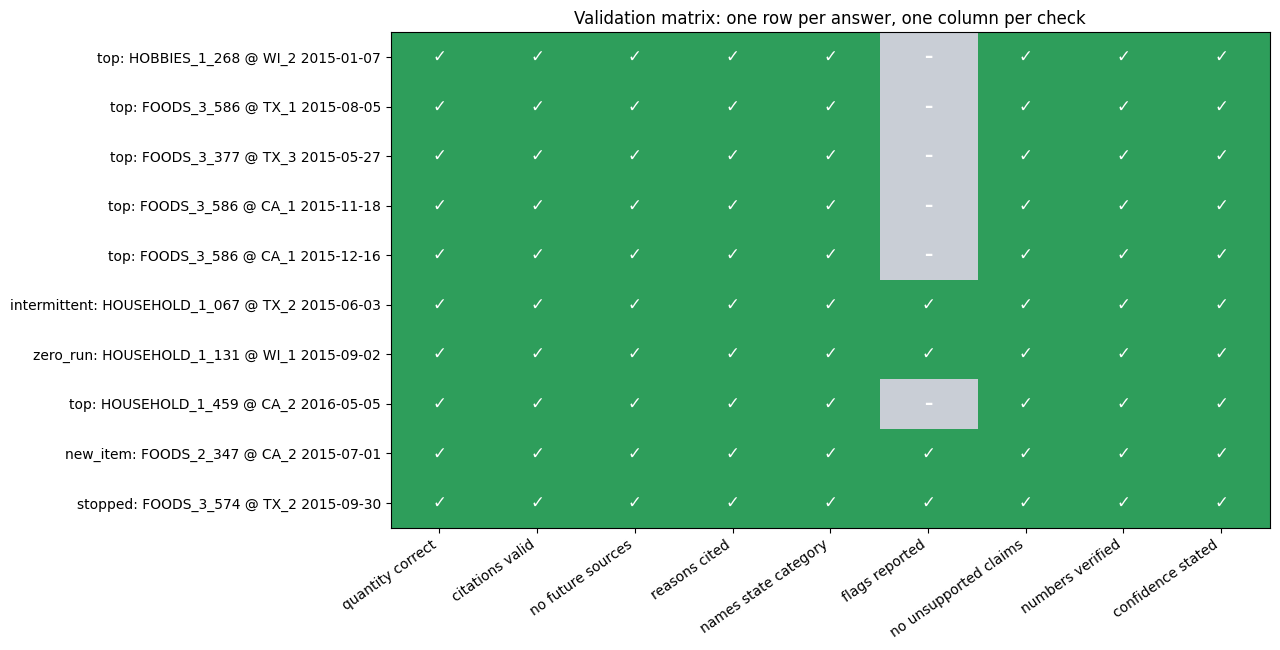

In [7]:
# The validation matrix as a picture for the slides (green pass, red fail, grey not applicable)
num = matrix.apply(lambda c: c.map(lambda v: np.nan if v is None or (isinstance(v, float) and np.isnan(v)) else float(bool(v))))
fig, ax = plt.subplots(figsize=(1.1 * len(ALL_CHECKS) + 3, 0.5 * len(num) + 1.6))
ax.imshow(num.fillna(0.5).to_numpy(), cmap=ListedColormap(["#D64545", "#C9CED6", "#2E9E5B"]), vmin=0, vmax=1, aspect="auto")
for i in range(num.shape[0]):
    for j in range(num.shape[1]):
        v = num.iat[i, j]
        ax.text(j, i, "–" if np.isnan(v) else ("✓" if v else "✗"), ha="center", va="center", color="white", fontsize=12, fontweight="bold")
ax.set_xticks(range(len(ALL_CHECKS)), [c.replace("_", " ") for c in ALL_CHECKS], rotation=35, ha="right")
ax.set_yticks(range(len(num)), [f"{s}: {i} @ {st} {d}" for s, i, st, d in num.index])
ax.set_title("Validation matrix: one row per answer, one column per check")
plt.tight_layout()
fig.savefig(out_path("validation_matrix.png"), dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# Read one answer with its item profile ([E1])
pick = 0                                     # change to read another scenario
a, r = agent_answers[pick], agent_rows[pick]
print(f"{a['scenario']}: {a['item']} @ {a['store']}, {a['as_of']} | forecast confidence {r['forecast_confidence']} | "
      f"explanation confidence {r['explanation_confidence']}\n")
print(a["prompt"].split("[E2]")[0].split("[E1]")[-1].strip() if a["prompt"] else "", "\n")
print(a["answer"] or "(no answer)")

top: HOBBIES_1_268 @ WI_2, 2015-01-07 | forecast confidence High | explanation confidence High

(item_profile, Forecast, segment and order data, published 2015-01-07, WI) Item profile: HOBBIES_1_268 at WI_2
Item profile for HOBBIES_1_268 at store WI_2 (Wisconsin), using data available on 2015-01-07. Demand segment from 2011-2014 sales: Lumpy, high volume (sells on average every 2.3 days). No LightGBM forecasts had been scored by this date, so its error for this segment is not yet known. Sales history: first sale 2011-01-31 (1438 days ago); last sale 2015-01-07; current run of zero-sale days: 0. Flags: none. Forecast confidence: High (Lumpy demand, no LightGBM results known yet; narrow forecast range (1.0 times the 14-day forecast)). 

Recommendation: Order 70 units.

Forecast confidence: High - Lumpy demand, no LightGBM results known yet; narrow forecast range (1.0 times the 14-day forecast) [E1]

Why:
- This is a Hobbies item in Wisconsin with lumpy, high-volume demand (average sale e

## 4. The managers' questions (tests 37–56) and their validation matrix
**Forecast-data lookup.** Questions about the forecasts themselves ("which store has the highest predicted demand?") can't be answered from documents. `route_question()` picks the right calculation, `forecast_lookup()` computes it from the forecast cube, and the result is given to the model as passage [E1] next to the retrieved evidence. M5 has **no inventory data**: shortage, excess and stock-out questions use an **assumed stock** of 7 days of each item's average sales over the last 4 weeks, and the answer must say so.

The first cell shows each lookup without calling the model. The second asks the agent and checks the answers:

| Check | Passes when |
|---|---|
| `lookup_correct` | `route_question()` chose the intended calculation (forecast questions) |
| `answer_correct` | The answer names the right result from the lookup (top store, category, item, peak day...) |
| `states_assumption` | Inventory questions say stock on hand is an assumption |
| `citations_valid`, `no_future_sources`, `reasons_cited`, `no_unsupported_claims`, `numbers_verified` | As for orders |
| `handles_missing` | No-answer questions (51–56) say the data doesn't contain it; the others don't wrongly claim there is no evidence |

Set `ASK_TESTS` to include tests 17–36 as well (20 more requests).

In [9]:
# Forecast-data lookups for the forecast questions (no model calls): what [E1] will contain and what a correct answer must name
for tid, q, as_of, st, types, terms, kind, lookup in TESTS:
    if kind != "data":
        continue
    routed, kw = route_question(q)
    lk = forecast_lookup(routed, as_of, **kw) if routed else None
    print(f"Test {tid} ({as_of}): {q}\n  routed to: {routed} (intended: {lookup}) | a correct answer names: {lk['keys'] if lk else '-'}")
    print("  " + (lk["text"][:400] + "..." if lk else "(no lookup)") + "\n")

Test 37 (2015-04-22): Which products are expected to have the highest demand over the next 7 days?
  routed to: top_items (intended: top_items) | a correct answer names: ['FOODS_3_586']
  Forecast data from the M5 forecasting model (LightGBM, forecast made on 2015-04-22) for the next 7 days, 2015-04-23 to 2015-04-29, 15,245 item-store series in the model's 50% sample. Highest predicted demand: FOODS_3_586 at TX_2 570.3 units; FOODS_3_586 at CA_3 459.1 units; FOODS_3_090 at TX_2 423.0 units; FOODS_3_090 at WI_3 375.9 units; FOODS_3_090 at TX_1 308.0 units; FOODS_3_555 at TX_2 301.6 ...

Test 38 (2015-07-15): Which product category has the highest predicted demand across all stores?
  routed to: by_category (intended: by_category) | a correct answer names: ['FOODS', 'Foods']
  Forecast data from the M5 forecasting model (LightGBM, forecast made on 2015-07-15) for the next 7 days, 2015-07-16 to 2015-07-22, 15,245 item-store series in the model's 50% sample. Predicted demand by category, a

test 37: 6.2 s, explanation confidence High
test 38: 20.2 s, explanation confidence Medium
test 39: 45.4 s, explanation confidence Medium
test 40: 8.8 s, explanation confidence High
test 41: 22.9 s, explanation confidence High
test 42: 13.5 s, explanation confidence High
test 43: 13.0 s, explanation confidence Medium
test 44: 24.3 s, explanation confidence High
test 45: 10.1 s, explanation confidence Medium
test 46: 20.1 s, explanation confidence High
test 47: 14.3 s, explanation confidence High
test 48: 18.3 s, explanation confidence High
test 49: 29.0 s, explanation confidence High
test 50: 16.1 s, explanation confidence Medium
test 51: 12.7 s, explanation confidence High
test 52: 14.7 s, explanation confidence High
test 53: 9.2 s, explanation confidence High
test 54: 29.0 s, explanation confidence High
test 55: 13.5 s, explanation confidence High
test 56: 4.7 s, explanation confidence High


,,lookup_correct,answer_correct,states_assumption,citations_valid,no_future_sources,reasons_cited,no_unsupported_claims,numbers_verified,handles_missing,explanation_confidence,question
test,kind,,,,,,,,,,,
37,data,✓,✓,–,✓,✓,✓,✓,✓,✓,High,Which products are expected to have the highes...
38,data,✓,✓,–,✓,✓,✗,✓,✓,✓,Medium,Which product category has the highest predict...
39,data,✓,✓,–,✓,✓,✗,✓,✓,✓,Medium,Which Walmart store has the highest predicted ...
40,data,✓,✓,–,✓,✓,✓,✓,✓,✓,High,How does predicted demand change throughout th...
41,data,✓,✓,–,✓,✓,✓,✓,✓,✓,High,Which products show the largest differences in...
42,data,✓,✓,✓,✓,✓,✓,✓,✓,✓,High,Which products have the greatest risk of runni...
43,data,✓,✓,✓,✓,✓,✗,✓,✓,✓,Medium,How does the risk of stockouts change over the...
44,data,✓,✓,✓,✓,✓,✓,✓,✓,✓,High,Which products should we prioritize for replen...
45,data,✓,✓,✓,✓,✓,✗,✓,✓,✓,Medium,Which stores should receive additional invento...


Pass rate by check: {'lookup_correct': '100%', 'answer_correct': '100%', 'states_assumption': '100%', 'citations_valid': '100%', 'no_future_sources': '100%', 'reasons_cited': '80%', 'no_unsupported_claims': '95%', 'numbers_verified': '100%', 'handles_missing': '100%'}
Explanation confidence: {'High': 15, 'Medium': 5}
Not answered: 0 (errors: 0)


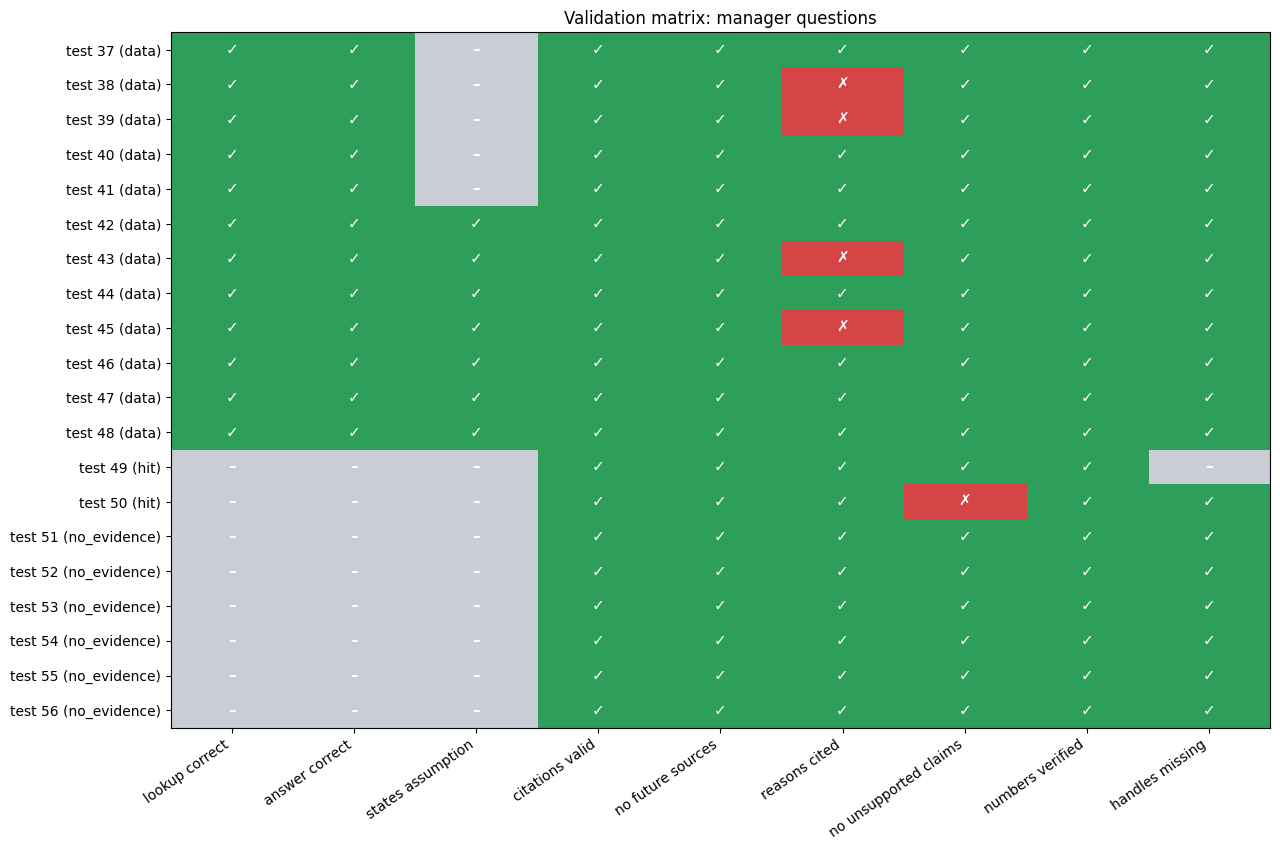

In [10]:
ASK_TESTS = [x for x in TESTS if x[0] >= 37]          # e.g. [x for x in TESTS if x[0] >= 17] for all 40 manager questions
MISSING_WORDS = ("no supporting evidence", "does not contain", "doesn't contain", "not in the data", "cannot be answered", "not available")
ASSUMPTION_WORDS = ("assum", "no inventory data", "not in the data", "inventory is not", "does not include inventory", "estimate")
_rt = out_path("retrieval_test_results.csv")
retrieval_ok = dict(zip(*pd.read_csv(_rt)[["test", "passed"]].T.values)) if os.path.exists(_rt) else {}

def validate_question(answer, res, kind, intended_lookup, retrieval_passed):
    if not answer or not answer.strip():
        return {"answered": False, "explanation_confidence": "No answer"}
    ev, lk, low = res["evidence"], res["lookup"], answer.lower()
    cited = sorted({int(x) for x in re.findall(r"E(\d+)", answer)})
    valid = [c for c in cited if 1 <= c <= len(ev)]
    bullets = [l for l in answer.splitlines() if l.strip().startswith(("-", "*", "•"))]
    why = [b for b in bullets if not re.search(r"nothing important|cannot tell|data cannot", b.lower())]
    uncited = [b.lower() for b in why if not re.search(r"E\d+", b)]
    says_missing = any(w in low for w in MISSING_WORDS)
    cited_share = round(float(np.mean([bool(re.search(r"E\d+", b)) for b in why])), 2) if why else 0.0
    bad_numbers = unverified_numbers(answer, res["prompt"])
    routed = lk["kind"] if lk else None
    row = {"answered": True,
           "lookup_correct": (routed == intended_lookup) if intended_lookup else (None if routed is None else False),
           "answer_correct": any(k.lower() in low for k in lk["keys"]) if (lk and lk["keys"]) else None,
           "states_assumption": any(w in low for w in ASSUMPTION_WORDS) if (lk and lk["uses_stock"]) else None,
           "citations_valid": len(cited) == len(valid),
           "no_future_sources": int(sum(ev.iloc[c - 1]["published"] > pd.Timestamp(res["as_of"]) for c in valid)) == 0,
           "reasons_cited": cited_share >= 0.6 or (kind == "no_evidence" and says_missing),
           "no_unsupported_claims": not any(OUTSIDE_RE.search(b) for b in uncited),
           "numbers_verified": len(bad_numbers) == 0,
           "handles_missing": says_missing if kind == "no_evidence" else (None if retrieval_passed is False else not low.lstrip().startswith(("answer: no supporting", "no supporting"))),
           "cited_share": cited_share, "passages_cited": len(valid), "unverified_numbers": ", ".join(f"{v:g}" for v in bad_numbers),
           "routed_to": routed, "words": len(answer.split())}
    crit = all(row[c] is not False for c in ["answer_correct", "citations_valid", "no_future_sources", "numbers_verified", "handles_missing"])
    rest = all(row[c] is not False for c in Q_CHECKS)
    row["explanation_confidence"] = "High" if crit and rest else "Medium" if crit else "Low"
    return row

Q_CHECKS = ["lookup_correct", "answer_correct", "states_assumption", "citations_valid", "no_future_sources", "reasons_cited",
            "no_unsupported_claims", "numbers_verified", "handles_missing"]
question_rows, question_answers = [], []
for tid, q, as_of, st, types, terms, kind, lookup in ASK_TESTS:
    t0, err, res = time.time(), None, None
    try:
        res = ask(q, as_of, st, verbose=False)
    except Exception as e:
        err = f"{type(e).__name__}: {str(e)[:200]}"
    row = {"test": tid, "kind": kind, "question": q[:90], "as_of": as_of, "state": st, "retrieval_passed": retrieval_ok.get(tid),
           "seconds": round(time.time() - t0, 1), "error": err,
           **(validate_question(res["answer"], res, kind, lookup, retrieval_ok.get(tid)) if res else {"answered": False, "explanation_confidence": "No answer"})}
    question_rows.append(row)
    question_answers.append({"test": tid, "question": q, "as_of": as_of, "state": st, "answer": res["answer"] if res else None,
                             "prompt": res["prompt"] if res else None})
    print(f"test {tid}: " + (err or f"{row['seconds']} s, explanation confidence {row['explanation_confidence']}"))
    time.sleep(PAUSE if res and res["answer"] else 0)

q_results = pd.DataFrame(question_rows)
q_matrix = q_results.set_index(["test", "kind"]).reindex(columns=Q_CHECKS)
display(q_matrix.apply(lambda c: c.map(symbol)).assign(explanation_confidence=q_results["explanation_confidence"].values,
                                                      question=q_results["question"].values))
q_ans = q_results[q_results["answered"] == True]
if len(q_ans):
    print("Pass rate by check:", {c: f"{100 * q_ans[c].dropna().astype(bool).mean():.0f}%" for c in Q_CHECKS if c in q_ans and q_ans[c].notna().any()})
    print("Explanation confidence:", q_ans["explanation_confidence"].value_counts().to_dict())
print(f"Not answered: {int((q_results['answered'] != True).sum())} (errors: {int(q_results['error'].notna().sum())})")

# Picture of the question matrix for the slides
qn = q_matrix.apply(lambda c: c.map(lambda v: np.nan if v is None or (isinstance(v, float) and np.isnan(v)) else float(bool(v))))
fig, ax = plt.subplots(figsize=(1.1 * len(Q_CHECKS) + 3, 0.35 * len(qn) + 1.6))
ax.imshow(qn.fillna(0.5).to_numpy(), cmap=ListedColormap(["#D64545", "#C9CED6", "#2E9E5B"]), vmin=0, vmax=1, aspect="auto")
for i in range(qn.shape[0]):
    for j in range(qn.shape[1]):
        v = qn.iat[i, j]
        ax.text(j, i, "–" if np.isnan(v) else ("✓" if v else "✗"), ha="center", va="center", color="white", fontsize=11, fontweight="bold")
ax.set_xticks(range(len(Q_CHECKS)), [c.replace("_", " ") for c in Q_CHECKS], rotation=35, ha="right")
ax.set_yticks(range(len(qn)), [f"test {tid} ({k})" for tid, k in qn.index])
ax.set_title("Validation matrix: manager questions")
plt.tight_layout(); fig.savefig(out_path("validation_matrix_questions.png"), dpi=200, bbox_inches="tight"); plt.show()

In [11]:
# Read one question's answer with its forecast lookup
TEST_ID = 39
a = next(x for x in question_answers if x["test"] == TEST_ID)
print(a["question"], "\n")
print(a["prompt"].split("[E2]")[0].split("[E1]")[-1].strip()[:1500] if a["prompt"] else "", "\n")
print(a["answer"] or "(no answer)")

Which Walmart store has the highest predicted demand over the next 7 days? 

(forecast_data, M5 forecasting model (forecast cube), published 2015-10-21, US) Forecast data: by store
Forecast data from the M5 forecasting model (LightGBM, forecast made on 2015-10-21) for the next 7 days, 2015-10-22 to 2015-10-28, 15,245 item-store series in the model's 50% sample. Predicted demand by store: CA_3 20,995 units; CA_1 14,435 units; TX_2 13,013 units; WI_2 12,753 units; WI_1 12,604 units; CA_2 12,546 units; TX_3 12,365 units; WI_3 10,514 units; TX_1 10,336 units; CA_4 8,983 units. 

Answer: CA_3 has the highest predicted demand over the next 7 days (2015-10-22 to 2015-10-28), with 20,995 units, ahead of CA_1 at 14,435 units and TX_2 at 13,013 units. These are the top store-level results listed by the M5 forecast made on the decision date.

Why:
- E1 ranks predicted demand by store for the next 7 days and lists CA_3 first at 20,995 units, above CA_1, TX_2, WI_2, and the other stores shown.

Wha

## 5. Save
| File | What it shows |
|---|---|
| `scenario_orders_v4.csv` | Each scenario's forecast, segment, computed and recommended quantity, hold, flags, confidence |
| `agent_validation_v4.csv` / `question_validation_v4.csv` | The validation matrices: every check for every answer, plus explanation confidence |
| `agent_answers_v4.csv` / `question_answers_v4.csv` | Every answer with its full prompt, for reading and hand scoring |
| `validation_matrix_v4.png` / `validation_matrix_questions_v4.png` | The matrices as pictures for the slides |

In [12]:
saved = []
def save(df, name, **kw):
    df.to_csv(out_path(name), **kw); saved.append(name)
save(scenario_table, "scenario_orders.csv", index=False)
if "results" in globals():
    save(results, "agent_validation.csv", index=False); save(pd.DataFrame(agent_answers), "agent_answers.csv", index=False)
    saved.append("validation_matrix.png")
if "q_results" in globals():
    save(q_results, "question_validation.csv", index=False); save(pd.DataFrame(question_answers), "question_answers.csv", index=False)
    saved.append("validation_matrix_questions.png")
print("Saved to", RAG_DIR + ":", ", ".join(os.path.basename(out_path(n)) for n in saved))

Saved to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG FILES/: scenario_orders_v4.csv, agent_validation_v4.csv, agent_answers_v4.csv, validation_matrix_v4.png, question_validation_v4.csv, question_answers_v4.csv, validation_matrix_questions_v4.png
